# Data Preparation for Machine Learning

This notebook provides a step-by-step guide to cleaning tree data from Grenoble in order to predict the planting year.

## Objective
Prepare the data to train a Machine Learning model that can predict missing tree planting years.

## Notebook Outline
1. Import libraries and load data  
2. Initial data exploration  
3. Data cleaning  
4. Save the data as a pickle file

## 1. Importing Libraries and Loading Data

We use several essential Python libraries for data analysis:
- pandas: for data manipulation  
- numpy: for numerical computations  
- matplotlib and seaborn: for visualization  
- sklearn: for preparing data for Machine Learning

In [1]:
# Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Loading the Data
df = pd.read_csv('/home/sami.chircop@Digital-Grenoble.local/Documents/ML1/data/arbres_grenoble_epsg4326.csv', sep=',', encoding='utf-8')

# Display the first few rows
print('Data preview:')
display(df.head())

# Dataset information
print('\nDataset information:')
df.info()

Data preview:


,elem_point_id,code,nom,genre,genre_desc,categorie,categorie_desc,sous_categorie,sous_categorie_desc,code_parent,...,diametrearbre,causeabattage,collectivite,stationmetro,hauteurarbre,portarbre,structure,forme,typenature,geo_point_2d
0,34835,ESP36318,AR36318,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167098421885385,5.740131798404362"
1,34836,ESP36319,AR36319,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16710682038838,5.740199792549315"
2,34837,ESP36320,AR36320,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167115270975415,5.740265608803635"
3,34838,ESP36321,AR36321,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16712715617142,5.740349032579623"
4,34839,ESP36322,AR36322,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167144245872265,5.740471081600832"



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 31670 entries, 0 to 31669
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   elem_point_id          31670 non-null  int64  
 1   code                   31670 non-null  str    
 2   nom                    31670 non-null  str    
 3   genre                  31670 non-null  str    
 4   genre_desc             31670 non-null  str    
 5   categorie              31670 non-null  str    
 6   categorie_desc         31670 non-null  str    
 7   sous_categorie         31670 non-null  str    
 8   sous_categorie_desc    31670 non-null  str    
 9   code_parent            31670 non-null  str    
 10  code_parent_desc       31670 non-null  str    
 11  adr_secteur            31670 non-null  int64  
 12  bien_reference         31670 non-null  str    
 13  genre_bota             30859 non-null  str    
 14  espece                 29370 non-null  str 

## 2. Initial Data Exploration

Before starting the cleaning process, it's crucial to understand our data:
- What columns are available?  
- What types of data do we have?  
- Are there any missing values?

In [3]:
# Descriptive Statistics
print(df.columns)
print(df.dtypes)
# Analysis of Missing Values
df.isna().sum(axis=0)

Index(['elem_point_id', 'code', 'nom', 'genre', 'genre_desc', 'categorie',
       'categorie_desc', 'sous_categorie', 'sous_categorie_desc',
       'code_parent', 'code_parent_desc', 'adr_secteur', 'bien_reference',
       'genre_bota', 'espece', 'variete', 'stadededeveloppement', 'equipe',
       'remarques', 'anneedeplantation', 'raisondeplantation',
       'traitementchenilles', 'courrier', 'identifiantplu',
       'typeimplantationplu', 'intituleprotectionplu', 'anneeabattage',
       'essouchement', 'diametrearbre', 'causeabattage', 'collectivite',
       'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme',
       'typenature', 'geo_point_2d'],
      dtype='str')
elem_point_id              int64
code                         str
nom                          str
genre                        str
genre_desc                   str
categorie                    str
categorie_desc               str
sous_categorie               str
sous_categorie_desc          str
code_parent 

elem_point_id                0
code                         0
nom                          0
genre                        0
genre_desc                   0
categorie                    0
categorie_desc               0
sous_categorie               0
sous_categorie_desc          0
code_parent                  0
code_parent_desc             0
adr_secteur                  0
bien_reference               0
genre_bota                 811
espece                    2300
variete                  27071
stadededeveloppement      4174
equipe                   31670
remarques                26358
anneedeplantation         2144
raisondeplantation       28383
traitementchenilles      29604
courrier                 31670
identifiantplu           31083
typeimplantationplu      26702
intituleprotectionplu    31083
anneeabattage            31670
essouchement             31670
diametrearbre            31670
causeabattage            31670
collectivite               718
stationmetro             29788
hauteura

### Visualisation of missing values

<Axes: >

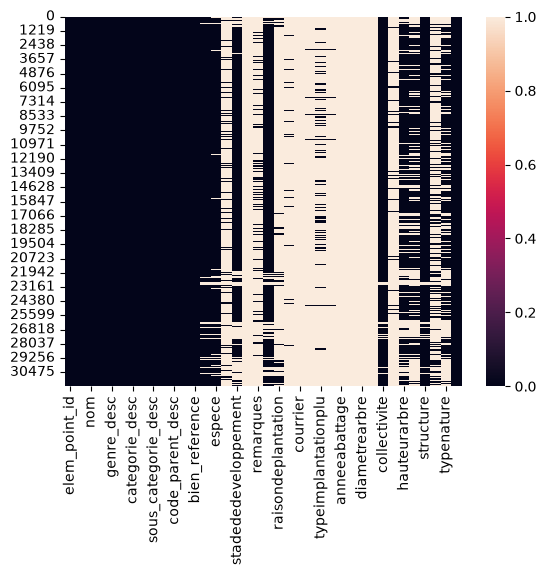

In [4]:
# Creation of a heatmap to visualize missing values
sns.heatmap(df.isna())

## 3. Data Cleaning

### 3.1 After the initial analysis, we will:
1. Remove rows without a planting year **'annedeplantation'**
2. Drop columns that are irrelevant for prediction  
3. Extract geographic coordinates

In [5]:
df['anneedeplantation'].notna()

0         True
1         True
2         True
3         True
4         True
         ...  
31665     True
31666     True
31667    False
31668    False
31669    False
Name: anneedeplantation, Length: 31670, dtype: bool

In [6]:
# 1. Remove rows without a planting year **'annedeplantation'**
df = df[df['anneedeplantation'].notna()]

### 🔍 3.2 Cleaning Unnecessary Columns

We will:

- Remove columns with more than **40% missing values**  
- Remove columns that are **too specific** (e.g., unique identifiers), which don't provide useful information for machine learning  
- Remove columns that contain redundant or unhelpful information

In [7]:
print(df.columns)
#print(df.nunique())
print(df.count())

Index(['elem_point_id', 'code', 'nom', 'genre', 'genre_desc', 'categorie',
       'categorie_desc', 'sous_categorie', 'sous_categorie_desc',
       'code_parent', 'code_parent_desc', 'adr_secteur', 'bien_reference',
       'genre_bota', 'espece', 'variete', 'stadededeveloppement', 'equipe',
       'remarques', 'anneedeplantation', 'raisondeplantation',
       'traitementchenilles', 'courrier', 'identifiantplu',
       'typeimplantationplu', 'intituleprotectionplu', 'anneeabattage',
       'essouchement', 'diametrearbre', 'causeabattage', 'collectivite',
       'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme',
       'typenature', 'geo_point_2d'],
      dtype='str')
elem_point_id            29526
code                     29526
nom                      29526
genre                    29526
genre_desc               29526
categorie                29526
categorie_desc           29526
sous_categorie           29526
sous_categorie_desc      29526
code_parent              29526

In [8]:
# 2 Remove overly specific columns, such as the 'elem_point_id' column
data = df.drop(['elem_point_id', 'code', 'code_parent', 'code_parent_desc', 'nom', 'genre', 'genre_desc', 'categorie', 'categorie_desc', 'bien_reference', 'remarques', 'equipe', 'courrier',
                'essouchement', 'diametrearbre', 'anneeabattage', 'causeabattage'], axis=1)

In [9]:
print(df.shape[0])

#Indique si la colonne contient plus de 40% de na
na_40pc = data.isna().sum(axis=0) / df.shape[0] > 0.4

#Sélectionne les index des colonnes concernées
data_clean = data.drop(na_40pc[na_40pc].index, axis=1)

29526


In [10]:
# 3. Extract geographic coordinates
geo_coord = data.pop('geo_point_2d')
geo_coord.map(lambda x: x.split()).head(1)
data[['Latitude', 'Longitude']] = geo_coord.str.split(',', expand=True).astype(float)

## 4. Save data to a pickle file

In [11]:
# Save data to a pickle file
data.to_pickle('/home/sami.chircop@Digital-Grenoble.local/Documents/ML1/data/trees.pkl')

## Conclusion

We have completed several important cleaning steps:
1. Removed irrelevant columns or those with too many missing values  
2. Extracted geographic coordinates  

The data is now ready for the next steps of the project.